# 2.4 Deflection, cracking, bond, anchorage and detailing

EC2 Sections 7, 8 and 9.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

## Deflection by span/depth ratio (EC2 7.4.2)

$$\frac ld = K\left[11+1.5\sqrt{f_{ck}}\frac{\rho_0}{\rho}+3.2\sqrt{f_{ck}}\left(\frac{\rho_0}{\rho}-1\right)^{3/2}\right]\ (\rho\le\rho_0), \qquad \frac ld = K\left[11+1.5\sqrt{f_{ck}}\frac{\rho_0}{\rho-\rho'}+\frac{\sqrt{f_{ck}}}{12}\sqrt{\frac{\rho'}{\rho_0}}\right]\ (\rho>\rho_0)$$

$\rho_0 = 10^{-3}\sqrt{f_{ck}}$; ρ is the steel **required** at mid-span (at the support for cantilevers).

| System (Table 7.4N / NA.5) | K |
|:--|:-:|
| Simply supported | 1.0 |
| End span of a continuous member; two-way slab continuous over one long side | 1.3 |
| Interior span | 1.5 |
| Flat slab | 1.2 |
| Cantilever | 0.4 |

Multiply by: 0.8 if b<sub>f</sub>/b<sub>w</sub> > 3; 7/l<sub>eff</sub> if the span exceeds 7 m and supports brittle partitions; and 310/σ<sub>s</sub> ≈ 500/(f<sub>yk</sub>A<sub>s,req</sub>/A<sub>s,prov</sub>).
**UK NA:** the steel-stress factor is capped at 1.5 (Note 5) and the final l/d at 40K (Note 6).

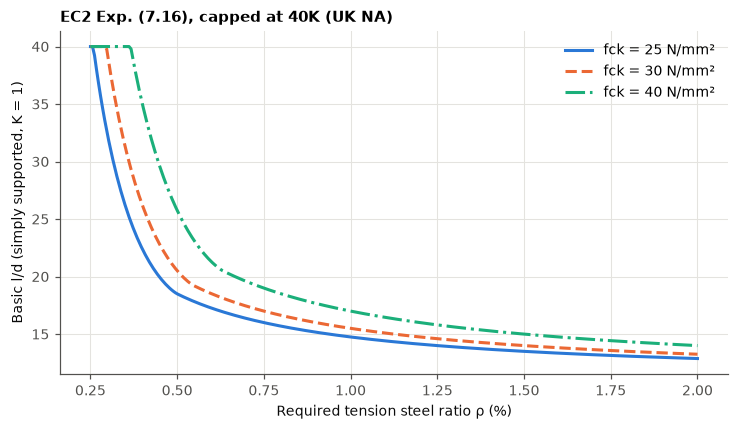

In [2]:
P.ld_chart()

## Crack control without calculation (EC2 7.3.3)

Limit w<sub>max</sub> = 0.3 mm for XC classes under the quasi-permanent combination (NA Table NA.4).
Slabs up to 200 mm thick, in bending, detailed to EC2 9.3: no specific measures needed (7.3.3(1)).

| σ<sub>s</sub> (N/mm² = MPa), w<sub>k</sub> = 0.3 mm | 160 | 200 | 240 | 280 | 320 | 360 |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|
| Max spacing (mm), Table 7.3N | 300 | 250 | 200 | 150 | 100 | 50 |
| Max bar size (mm), Table 7.2N | 32 | 25 | 16 | 12 | 10 | 8 |

Minimum steel for crack control: $A_{s,min}\,\sigma_s = k_c k f_{ct,eff}A_{ct}$ (Exp. 7.1).

## Bond and anchorage (EC2 8.4)

$$f_{bd} = 2.25\eta_1\eta_2 f_{ctd}, \quad l_{b,rqd} = \frac{\phi}{4}\frac{\sigma_{sd}}{f_{bd}}, \quad l_{bd} = \alpha_1\alpha_2\alpha_3\alpha_4\alpha_5\,l_{b,rqd}\ge l_{b,min}, \quad l_0 = \alpha_1\alpha_2\alpha_3\alpha_5\alpha_6 l_{b,rqd}\ge l_{0,min}$$

The sheets take every α = 1.0 unless stated (the conservative upper bound in Table 8.2).

In [3]:
rows = []
for phi in (8, 10, 12, 16, 20, 25, 32):
    r = [f"H{phi}"]
    for good in (True, False):
        fbd = 2.25 * (1.0 if good else 0.7) * 0.7 * 0.30 * 30 ** (2 / 3) / 1.5
        lb = phi / 4 * 500 / 1.15 / fbd
        r += [math.ceil(max(lb, .3 * lb, 10 * phi, 100) / 10) * 10, math.ceil(max(1.5 * lb, 15 * phi, 200) / 10) * 10]
    rows.append(r)
table(rows, ["Bar", "lbd good (mm)", "l0 good, α6 = 1.5", "lbd poor (mm)", "l0 poor, α6 = 1.5"], "C30/37, B500, full stress fyd, all α = 1.0 (EC2 Exp. 8.2 to 8.11)")

**C30/37, B500, full stress fyd, all α = 1.0 (EC2 Exp. 8.2 to 8.11)**

| Bar | lbd good (mm) | l0 good, α6 = 1.5 | lbd poor (mm) | l0 poor, α6 = 1.5 |
|:--|:-:|:-:|:-:|:-:|
| H8 | 290 | 430 | 410 | 620 |
| H10 | 360 | 540 | 520 | 770 |
| H12 | 430 | 650 | 620 | 920 |
| H16 | 580 | 860 | 820 | 1230 |
| H20 | 720 | 1080 | 1030 | 1540 |
| H25 | 900 | 1350 | 1280 | 1920 |
| H32 | 1150 | 1720 | 1640 | 2460 |


## Bar areas

In [4]:
table([[f"H{p}"] + [round(D.area(p, n)) for n in range(1, 9)] for p in (8, 10, 12, 16, 20, 25, 32)], ["Bars (mm²)"] + [str(n) for n in range(1, 9)])
table([[f"H{p}"] + [round(D.area(p) * 1000 / sp) for sp in (100, 125, 150, 175, 200, 225, 250, 300)] for p in (8, 10, 12, 16, 20)], ["mm²/m at spacing"] + [str(x) for x in (100, 125, 150, 175, 200, 225, 250, 300)])

| Bars (mm²) | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| H8 | 50 | 101 | 151 | 201 | 251 | 302 | 352 | 402 |
| H10 | 79 | 157 | 236 | 314 | 393 | 471 | 550 | 628 |
| H12 | 113 | 226 | 339 | 452 | 565 | 679 | 792 | 905 |
| H16 | 201 | 402 | 603 | 804 | 1005 | 1206 | 1407 | 1608 |
| H20 | 314 | 628 | 942 | 1257 | 1571 | 1885 | 2199 | 2513 |
| H25 | 491 | 982 | 1473 | 1963 | 2454 | 2945 | 3436 | 3927 |
| H32 | 804 | 1608 | 2413 | 3217 | 4021 | 4825 | 5630 | 6434 |


| mm²/m at spacing | 100 | 125 | 150 | 175 | 200 | 225 | 250 | 300 |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| H8 | 503 | 402 | 335 | 287 | 251 | 223 | 201 | 168 |
| H10 | 785 | 628 | 524 | 449 | 393 | 349 | 314 | 262 |
| H12 | 1131 | 905 | 754 | 646 | 565 | 503 | 452 | 377 |
| H16 | 2011 | 1608 | 1340 | 1149 | 1005 | 894 | 804 | 670 |
| H20 | 3142 | 2513 | 2094 | 1795 | 1571 | 1396 | 1257 | 1047 |


## Detailing rules used in the sheets

| Member | Rule | Reference |
|:--|:--|:--|
| All | Clear bar spacing ≥ max(φ, d<sub>g</sub> + 5, 20 mm) | EC2 8.2(2) |
| Slab | Main bars ≤ 3h, 400 mm; at maximum moment ≤ 2h, 250 mm | EC2 9.3.1.1(3) |
| Slab | Secondary bars ≥ 20% of main; ≤ 3.5h, 450 mm; at maximum moment ≤ 3h, 400 mm | EC2 9.3.1.1(2), (3) |
| Slab | Simple support: at least half the span steel continues to the support | EC2 9.3.1.2(1) |
| Slab | Partial fixity not analysed: top steel ≥ 25% of span moment (15% at an end support), extending 0.2 × span | EC2 9.3.1.2(2) |
| Beam | Monolithic end support: hogging ≥ 25% of span moment (UK NA; EC2 recommends 15%) | EC2 9.2.1.2(1), NA |
| Beam | At least 25% of span steel anchored at an end support | EC2 9.2.1.4(1) |
| Column | Bars ≥ 12 mm (UK NA; EC2 8 mm); A<sub>s</sub> ≥ max(0.10N<sub>Ed</sub>/f<sub>yd</sub>, 0.002A<sub>c</sub>); ≤ 0.04A<sub>c</sub> | EC2 9.5.2, NA |
| Column | Links ≥ max(6, φ/4); spacing ≤ min(20φ, b, 400), × 0.6 near beams and laps | EC2 9.5.3 |
| Footing | Bars ≥ 8 mm; anchorage checked with the inclined-crack model | EC2 9.8.2 |

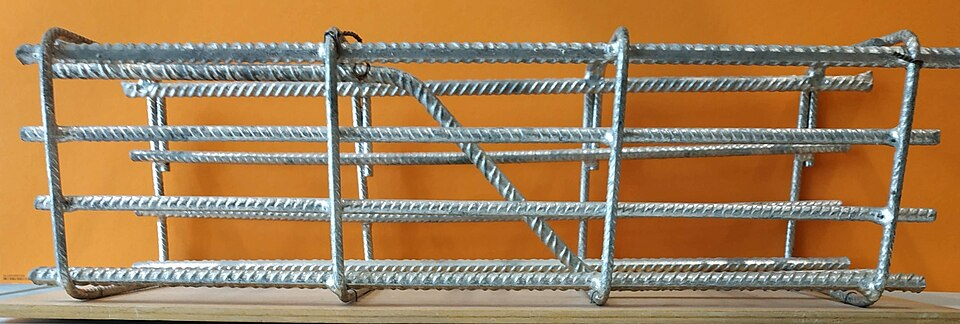

*A lintel reinforcement cage seen from the side: bottom bars, top bars, links and one bent-up bar.* <br><small>Photo: Patrick Oberdörfer, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Bewehrungskorb_Sturz_seitlich.jpg).</small>

In [5]:
photo("beam_cage", "A lintel reinforcement cage seen from the side: bottom bars, top bars, links and one bent-up bar.")